# Shape Transformation using Variational Implicit Functions Notebook Implementation

Notebook implementation by Andy Thai

Sample implementation: https://github.com/fiji/VIB/blob/master/src/main/java/Implicit_Interpolate_Binary.java

Set up our interpolation function f(x):

$
f(x) = \sum_{j=1}^k d_j \phi(x - c_j) + P(x) 
$

<br>

We want to solve for $d_j$ and the coefficients of $P(x)$. To solve for $d_j$, we can substitute the right side of the above equation for $f(\textbf{c}_i)$ for the constraints $h_i = f(\textbf{c}_i)$ to get the below equation, where $h_i$ is the height value:

$
h_i = \sum_{j=1}^k d_j \phi(c_i - c_j) + P(c_i) 
$

<br>
We can represent this equation as the matrix in the 3D interpolation case, where $h_i$ is corresponding x or y coordinate, depending on whether you are solving for $f'_{x}$ or $f'_{y}$:

$
\begin{bmatrix}
\phi_{11} & \phi_{12} & \ldots & \phi_{1k} & 1 & c_1^x & c_1^y & c_1^z \\
\phi_{21} & \phi_{22} & \ldots & \phi_{2k} & 1 & c_2^x & c_2^y & c_2^z \\
\vdots & \vdots & \ldots & \vdots & \vdots & \vdots & \vdots & \vdots \\
\phi_{k1} & \phi_{k2} & \ldots & \phi_{kk} & 1 & c_k^x & c_k^y & c_k^z \\
1 & 1 & \ldots & 1 & 0 & 0 & 0 & 0 \\
c_1^x & c_2^x & \ldots & c_k^x & 0 & 0 & 0 & 0 \\
c_1^y & c_2^y & \ldots & c_k^y & 0 & 0 & 0 & 0 \\
c_1^z & c_2^z & \ldots & c_k^z & 0 & 0 & 0 & 0 \\
\end{bmatrix}
\begin{bmatrix}
d_1 \\ 
d_2 \\
\vdots \\
d_k \\
p_0 \\
p_1 \\
p_2 \\
p_3 \\
\end{bmatrix}
=
\begin{bmatrix}
h_1 \\ 
h_2 \\
\vdots \\
h_k \\
0 \\
0 \\
0 \\
0 \\
\end{bmatrix}
$

<br>
Let $\phi_{ij} = \phi(\textbf{c}_i - \textbf{c}_j)$

$p_0, p_1, p_2, p_3$ can also be written as $p_0, p_x, p_y, p_z$ respectively.



In [1]:
%load_ext autoreload
%autoreload 2

## Import libraries

In [2]:
# Standard library test
import time
from pprint import pprint
import glob

# Third-party libraries
import numpy as np
import matplotlib.pyplot as plt
import scipy
#from jupyterthemes import jtplot; jtplot.style()

# My libraries
from modules.implicit import ImplicitFunction
import modules.utils as utils

## Setup sample 3D example

In [3]:
#train = sorted(glob.glob("data/MM-WHS_2017/train/images/mr_train_1002_*.npy"))
lv = "data/npy/lv.npy"
#rv = "data/npy/rv.npy"
#train = np.array([np.load(f) for f in train])
volume = np.load(lv) #+ np.load(rv) #+ \
         #np.array([np.load(f) for f in la]) + np.array([np.load(f) for f in ra]) #+ \
         #np.array([np.load(f) for f in pa]) + np.array([np.load(f) for f in aa])

where_1 = np.where(volume != 0)
volume[where_1] = 1

#np.save("data/npy/both.npy", volume)
# Setup 3D volume
M = volume[15, 2:]
print(M.shape)
# Remove portions that give inf/NaN
#to_keep = np.array([i for i in range(102) if i not in [26, 98, 101]])
#M = M[to_keep, :, :]
# Condense to 5 slices
#to_keep = np.array([20, 25, 50])

(8, 216, 256)


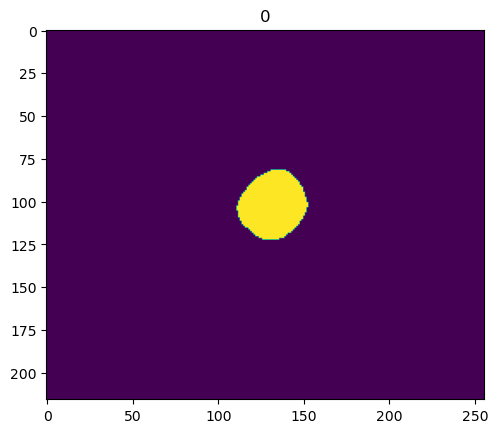

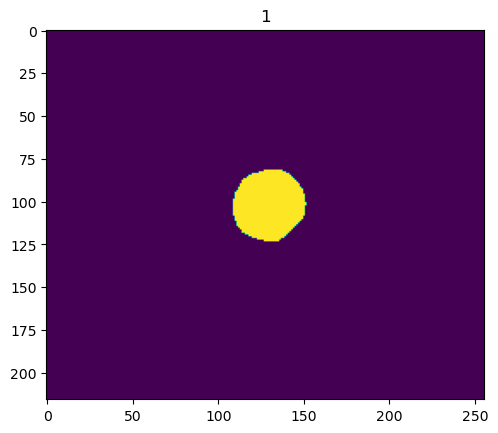

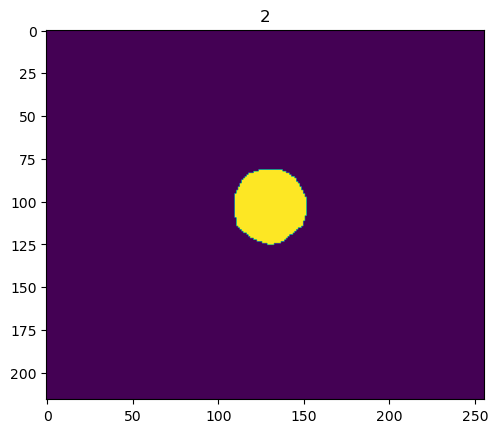

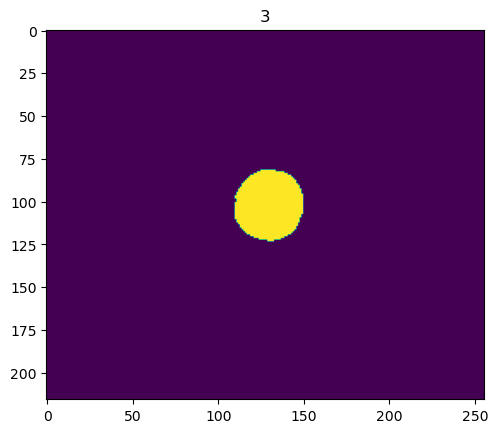

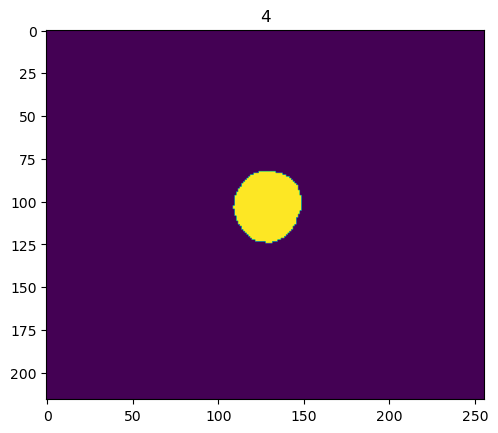

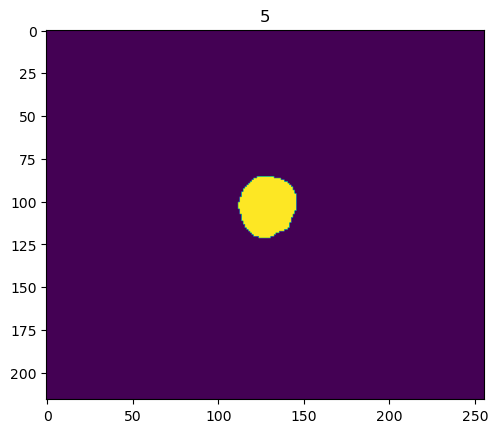

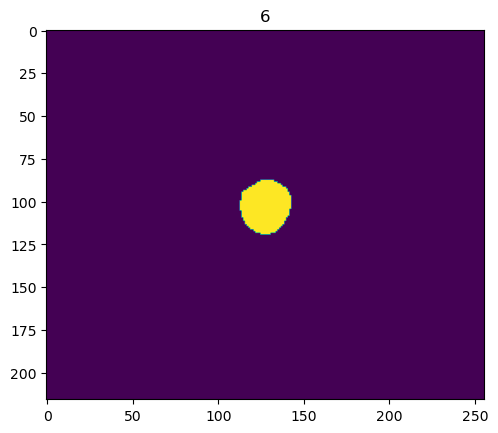

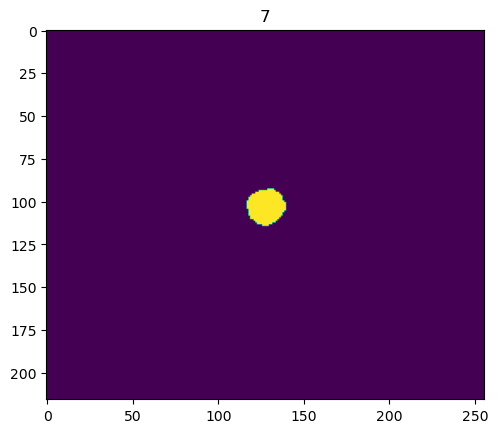

In [4]:
#i = 1
for i in range(M.shape[0]):
    plt.title(str(i))
    plt.imshow(M[i]); plt.show()

### Test implementation for 3D interpolation input

DEBUG: Creating constraints.
(6329, 3)
DEBUG: Finished creating constraints.
Elapsed time: 2.970634937286377

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/6329 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 8.552649736404419

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 2.4444167613983154
Elapsed time: 14.276377439498901


Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

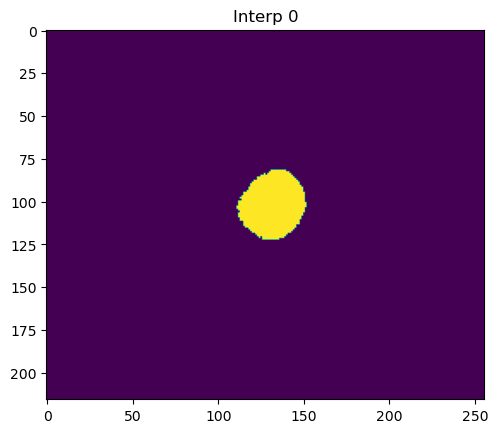

Elapsed time: 71.34972715377808
0 with boundary constraints


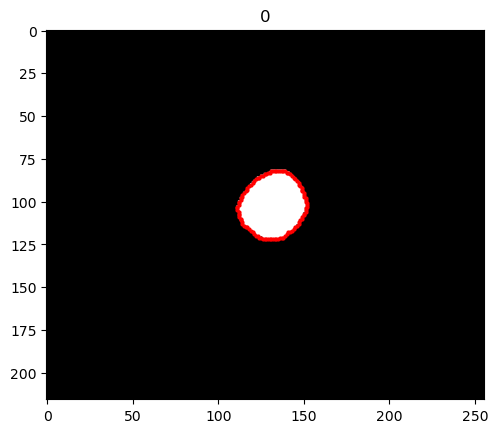

0 with normal constraints


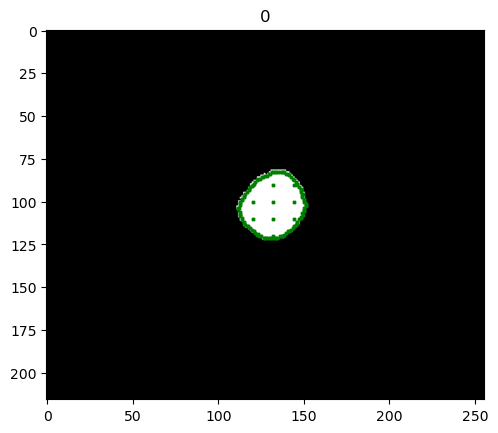

0 with outside constraints


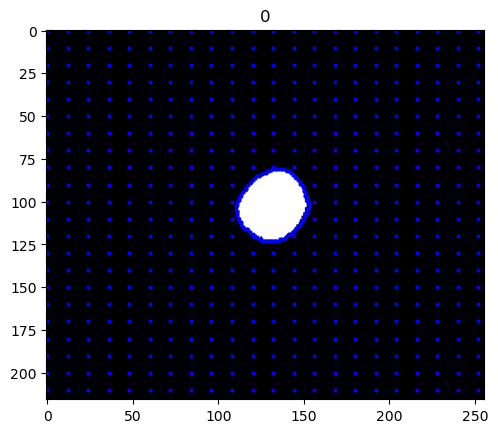

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

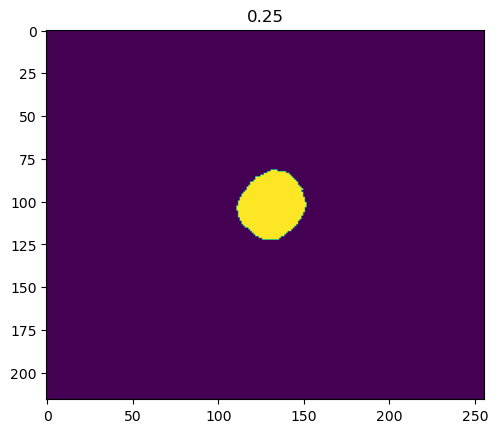

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

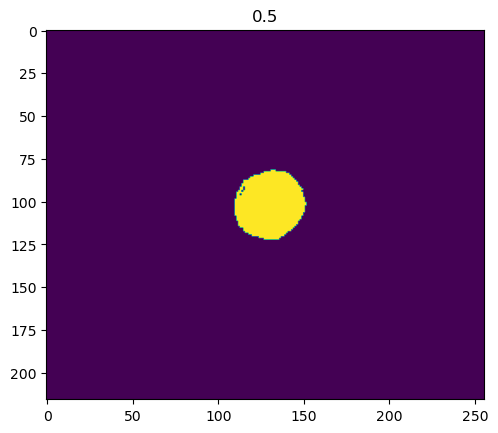

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

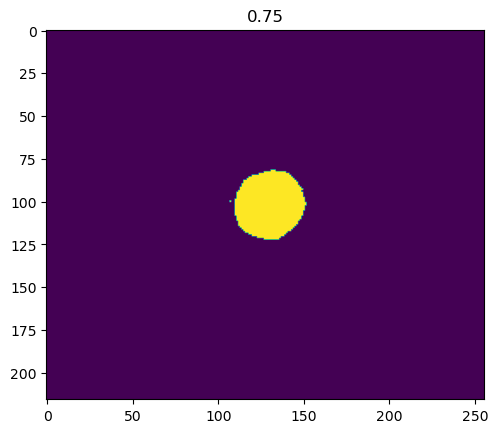

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

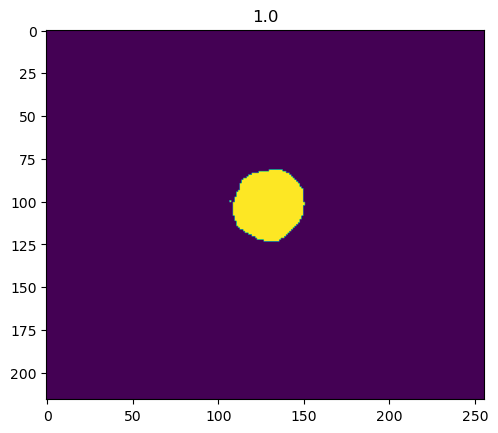

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

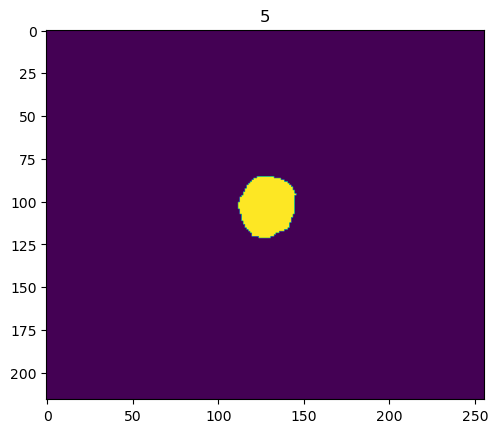

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

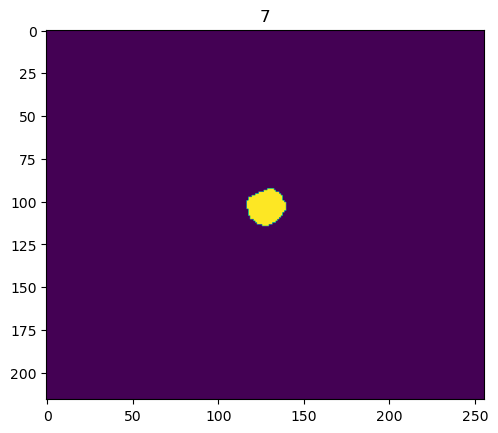

In [5]:
# Create implicit surface
start = time.time()
imp = ImplicitFunction(M, tmax=7)
end = time.time() - start
print(f"Elapsed time: {end}")

# Interpolate image at some parametrization t
start = time.time()
img = imp.interpolate(0)
plt.title("Interp 0"); plt.imshow(img); plt.show()
end = time.time() - start
print(f"Elapsed time: {end}")

print("0 with boundary constraints")
imp.data.show(0, img, [0])
print("0 with normal constraints")
imp.data.show(0, img, [1])
print("0 with outside constraints")
imp.data.show(0, img, [-1])

img = imp.interpolate(0.25)
plt.title("0.25"); plt.imshow(img); plt.show()

img = imp.interpolate(0.5)
plt.title("0.5"); plt.imshow(img); plt.show()

img = imp.interpolate(0.75)
plt.title("0.75"); plt.imshow(img); plt.show()

img = imp.interpolate(1)
plt.title("1.0"); plt.imshow(img); plt.show()

img = imp.interpolate(5)
plt.title("5"); plt.imshow(img); plt.show()

img = imp.interpolate(7)
plt.title("7"); plt.imshow(img); plt.show()

## 12-15-23 Test

(8, 216, 256)


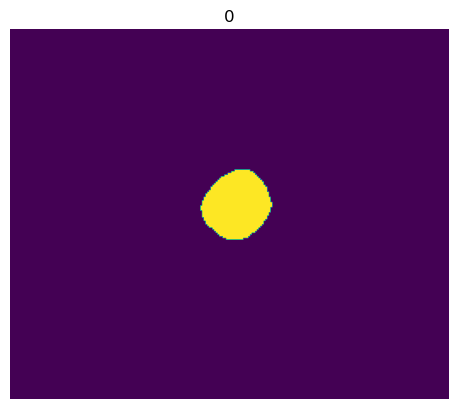

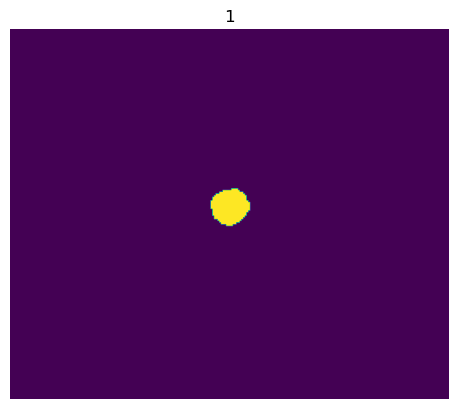

In [21]:
M2 = [M[0], M[7]]
M2 = np.array(M2)
print(M.shape)

for i in range(M2.shape[0]):
    plt.title(str(i))
    plt.axis(False)
    plt.imshow(M2[i])
    plt.show()

DEBUG: Creating constraints.
(1471, 3)
DEBUG: Finished creating constraints.
Elapsed time: 0.6920886039733887

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/1471 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 0.4411125183105469

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.025765180587768555
Elapsed time: 1.2118611335754395


Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

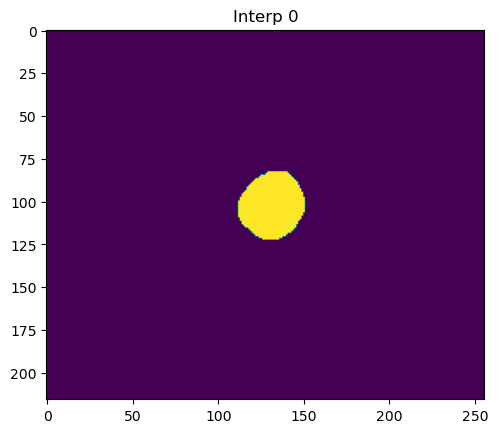

Elapsed time: 17.30638074874878
0 with boundary constraints


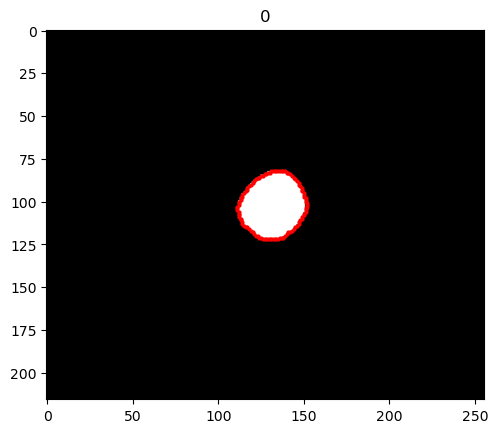

0 with normal constraints


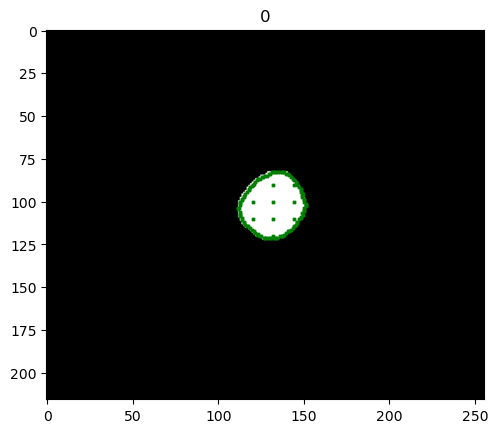

0 with outside constraints


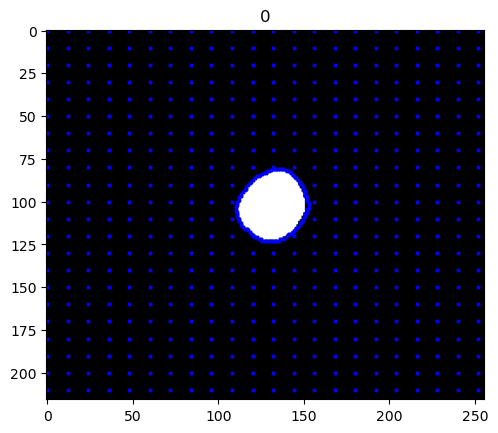

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

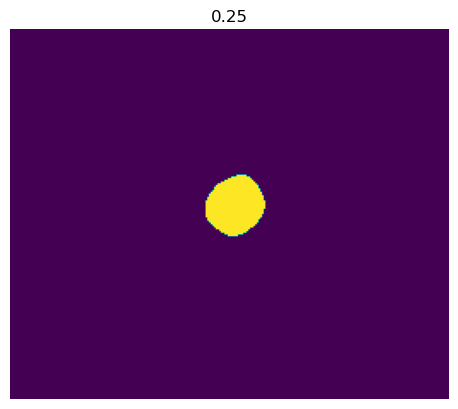

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

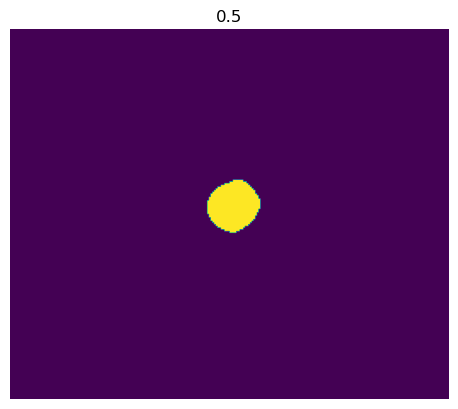

In [22]:
# Create implicit surface
start = time.time()
imp = ImplicitFunction(M2, tmax=1)
end = time.time() - start
print(f"Elapsed time: {end}")

# Interpolate image at some parametrization t
start = time.time()
img = imp.interpolate(0)
plt.title("Interp 0"); plt.imshow(img); plt.show()
end = time.time() - start
print(f"Elapsed time: {end}")

print("0 with boundary constraints")
imp.data.show(0, img, [0])
print("0 with normal constraints")
imp.data.show(0, img, [1])
print("0 with outside constraints")
imp.data.show(0, img, [-1])

img = imp.interpolate(0.25)
plt.title("0.25"); plt.imshow(img); plt.axis(False); plt.show()

img = imp.interpolate(0.5)
plt.title("0.5"); plt.imshow(img); plt.axis(False); plt.show()

In [7]:
volume.shape

(30, 10, 216, 256)

In [10]:
import cv2

In [15]:
min_vol = np.inf
max_vol = -np.inf
min_t = -1
max_t = -1
for i in range(volume.shape[0]):
    curr_vol = volume[i, :]
    computed_vol = np.count_nonzero(curr_vol)
    if computed_vol > max_vol:
        max_t = i
        max_vol = computed_vol
    if computed_vol < min_vol:
        min_t = i
        min_vol = computed_vol
print('min_t', min_t)
print('max_t', max_t)
print('min_vol', min_vol)
print('max_vol', max_vol)
print('ef', min_vol/max_vol)

min_t 11
max_t 0
min_vol 9214
max_vol 11917
ef 0.7731811697574893


## Test 4D Interp

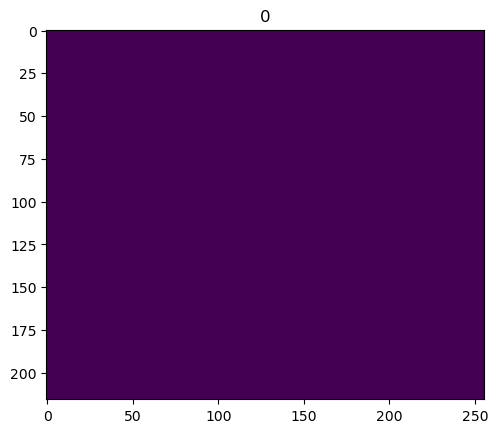

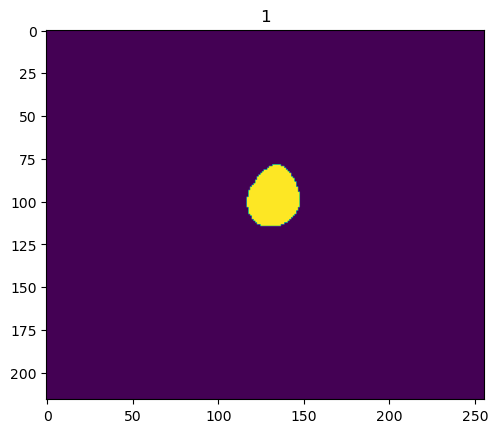

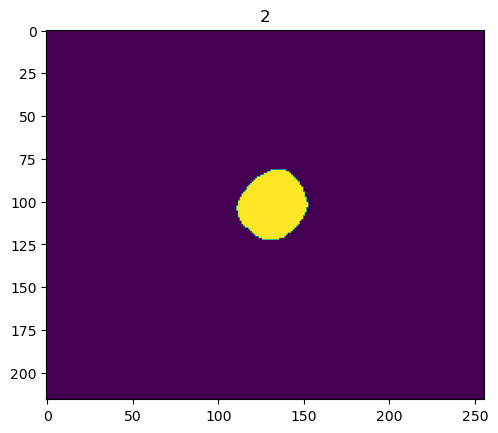

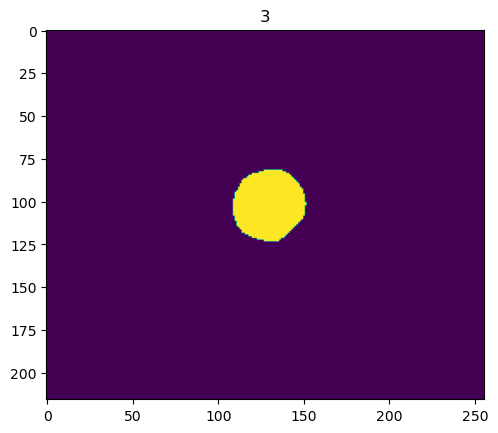

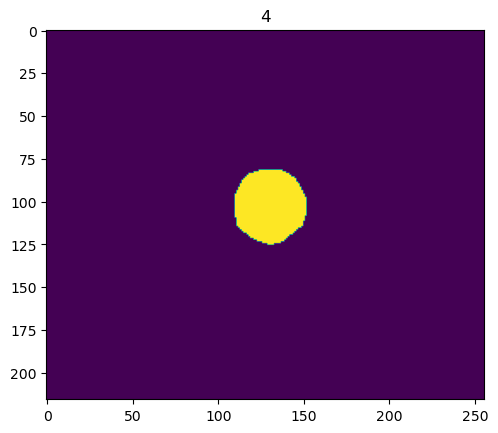

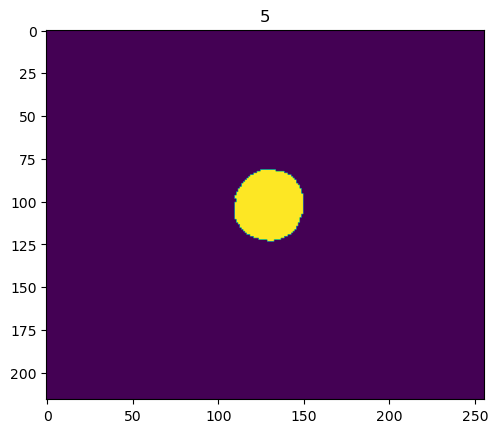

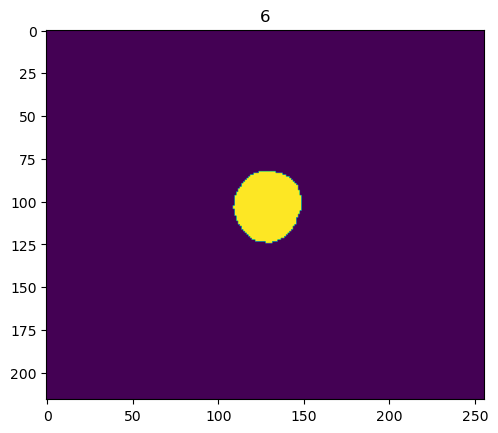

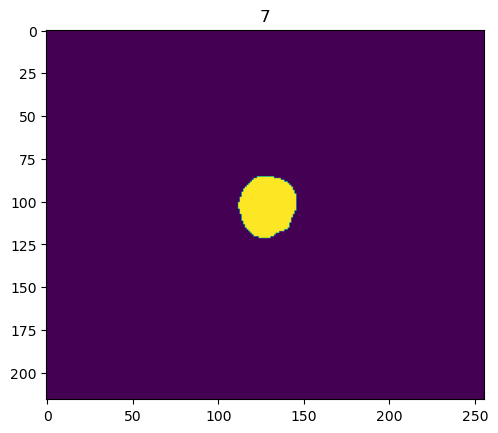

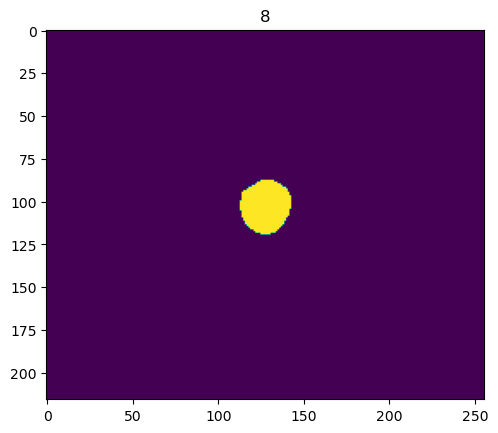

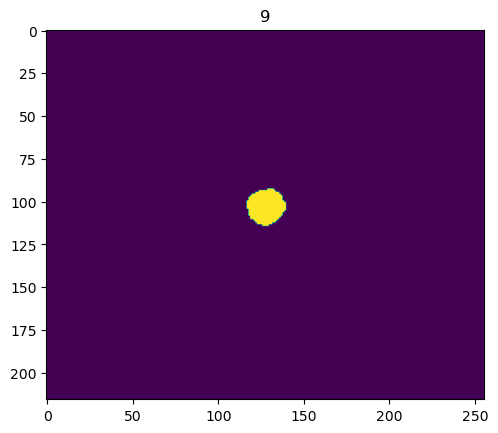

In [17]:
for i in range(len(Ma)):
    plt.title(str(i))
    plt.imshow(Mb[i])
    plt.show()

(2, 10, 216, 256)
DEBUG: Creating constraints.
(5784, 4)
DEBUG: Finished creating constraints.
Elapsed time: 0.3179965019226074

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/5784 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 6.330703020095825

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 1.1870651245117188
Output dimensions: (10, 216, 256)
Threshold: 0.0


Interpolating volume stack:   0%|          | 0/2160 [00:00<?, ?it/s]

(10, 216, 256)


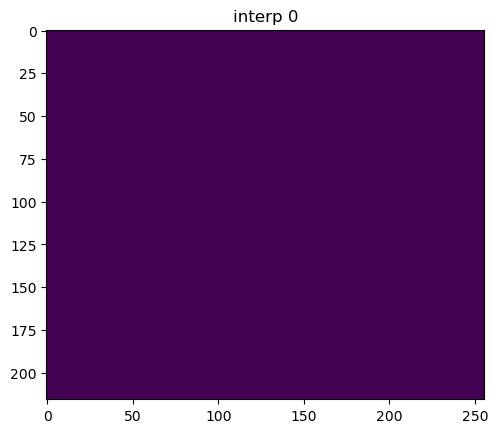

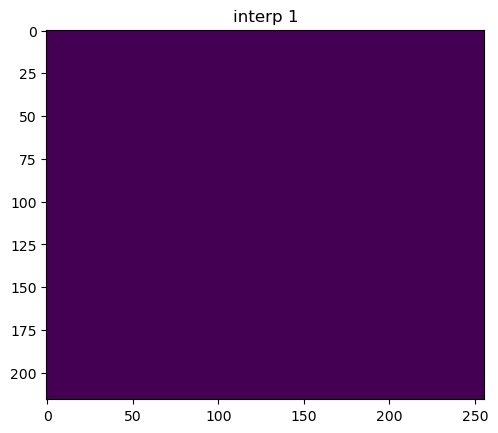

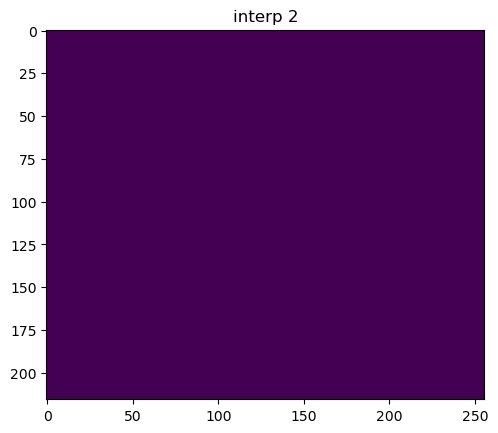

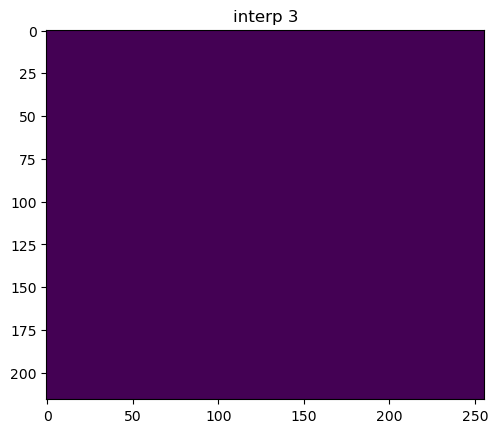

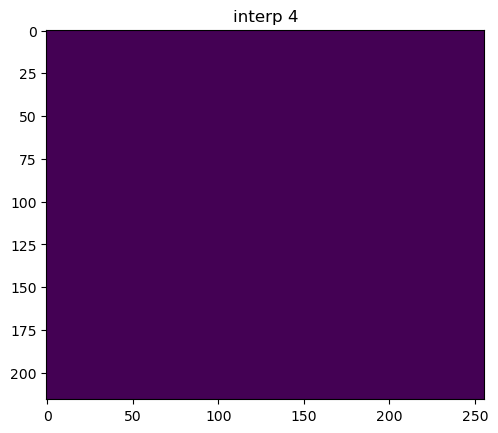

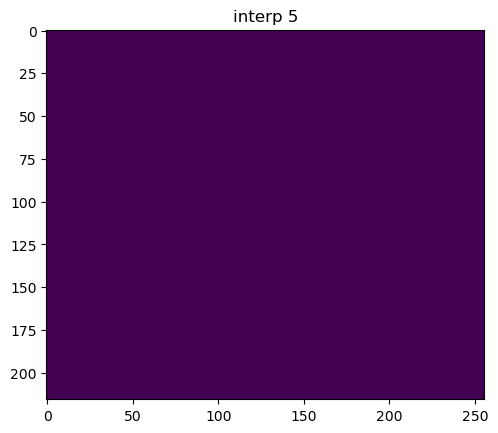

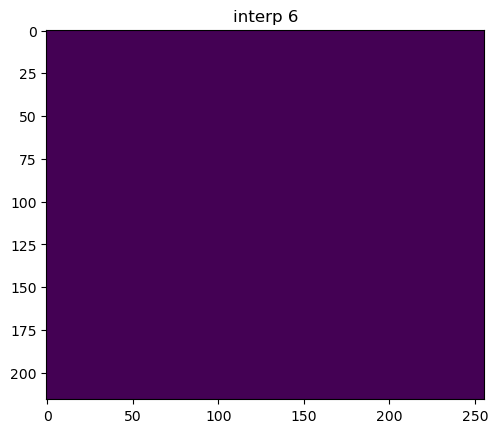

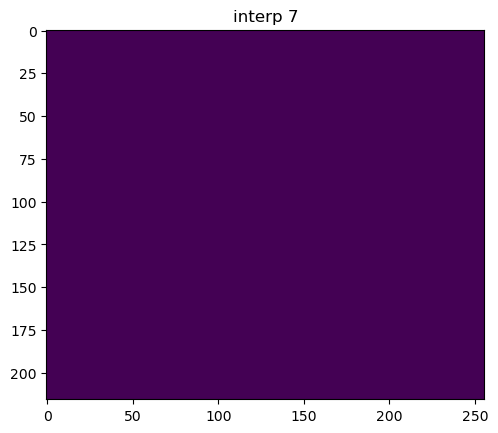

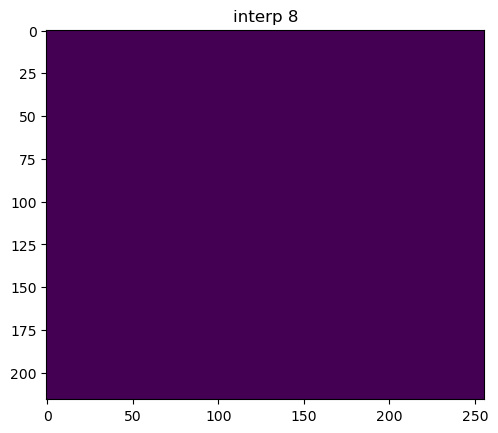

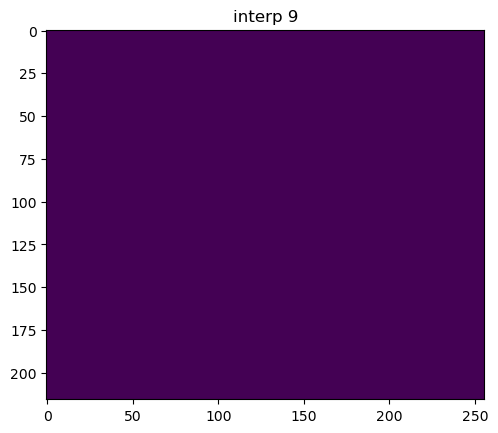

In [11]:
# Try 3D to 3D
Ma = volume[0, 0:]
Mb = volume[15, 0:]
Mab = np.array([Ma, Mb])
np.save('output/4DLV/4DLV_M0.npy', Ma)
np.save('output/4DLV/4DLV_M15.npy', Mb)
print(Mab.shape)

"""
for i in range(Ma.shape[0]):
    fig, ax = plt.subplots(1, 2)
    ax[0].imshow(Ma[i])
    ax[1].imshow(Mb[i])
    plt.show()
""" 
imp = ImplicitFunction(Mab, tmax=1)
img = imp.interpolate(0.5)

print(img.shape)

for i in range(img.shape[0]):
    plt.imshow(img[i])
    plt.title('interp ' + str(i))
    plt.show()

In [ ]:
from skimage.filters import median
from skimage.morphology import disk

testimg = img.copy()[0, 4]
imgmedian = median(testimg, disk(3))

In [30]:
np.save('output/4DLV/4DLV_interp.npy', img)

## 12-15-23 end

DEBUG: Creating constraints.
DEBUG: Finished creating constraints.
Elapsed time: 16.251675128936768

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/9428 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 22.801040410995483

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 2.1656744480133057
Elapsed time: 49.34825253486633


Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

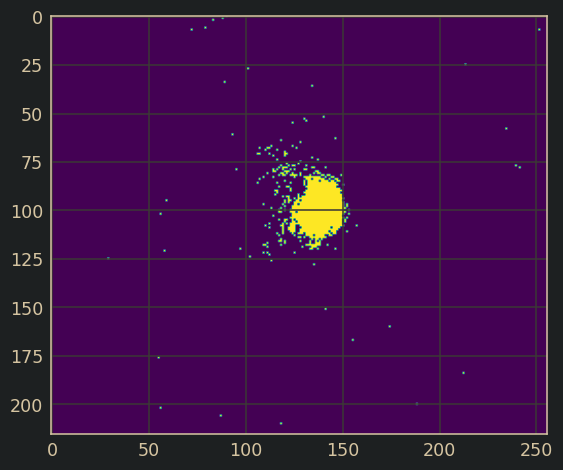

Elapsed time: 135.94837260246277


Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

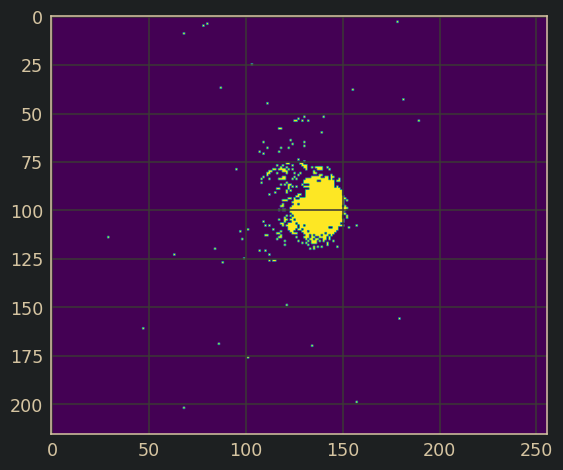

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

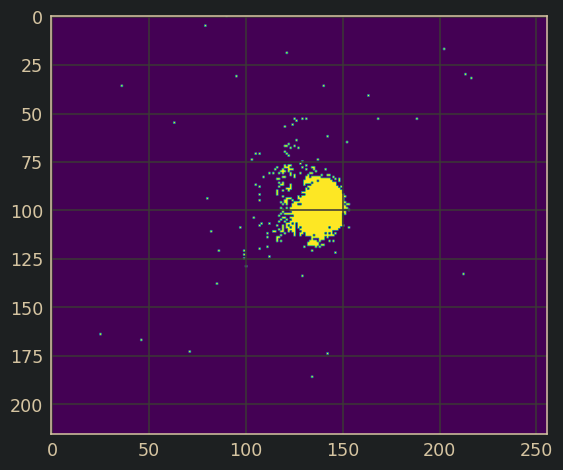

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

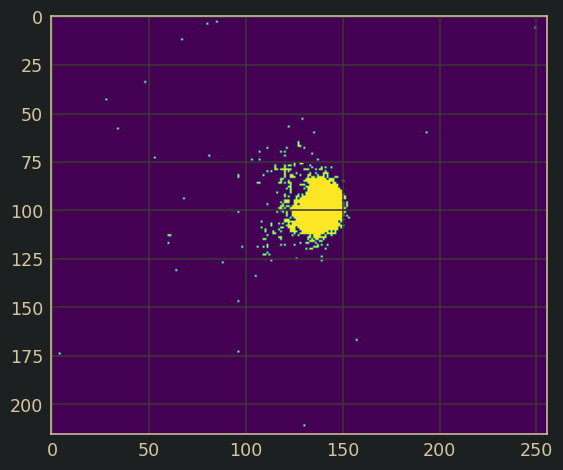

In [7]:
# Create implicit surface
start = time.time()
imp = ImplicitFunction(M, tmax=1)
end = time.time() - start
print(f"Elapsed time: {end}")

# Interpolate 2D image at some parametrization t
start = time.time()
img = imp.interpolate(0)
plt.imshow(img); plt.show()
end = time.time() - start
print(f"Elapsed time: {end}")


img = imp.interpolate(0.25)
plt.imshow(img); plt.show()

img = imp.interpolate(0.75)
plt.imshow(img); plt.show()

img = imp.interpolate(1.0)
plt.imshow(img); plt.show()

### Show original input volume slices

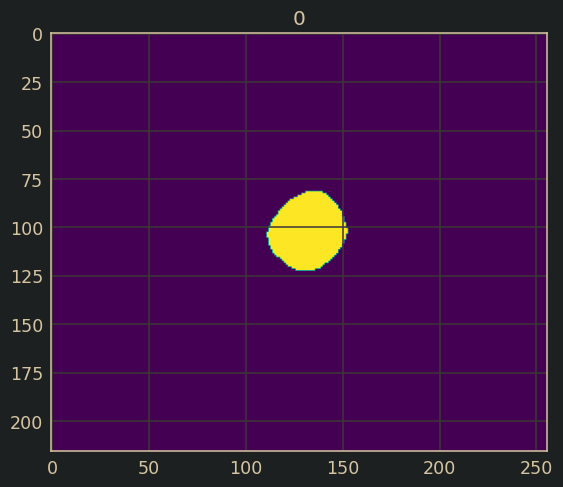

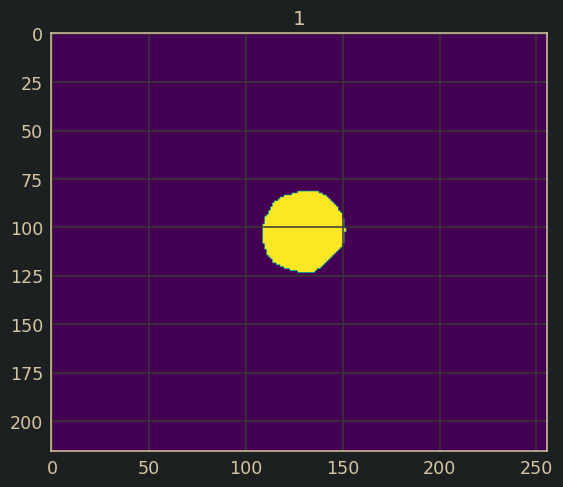

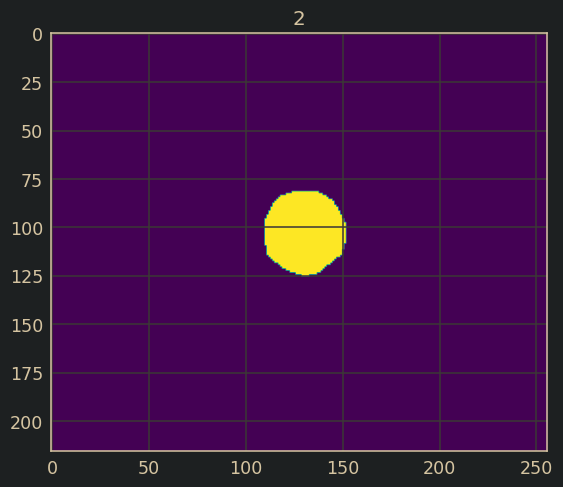

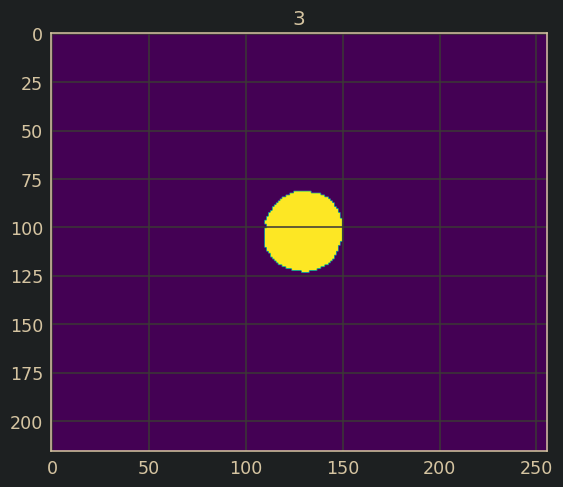

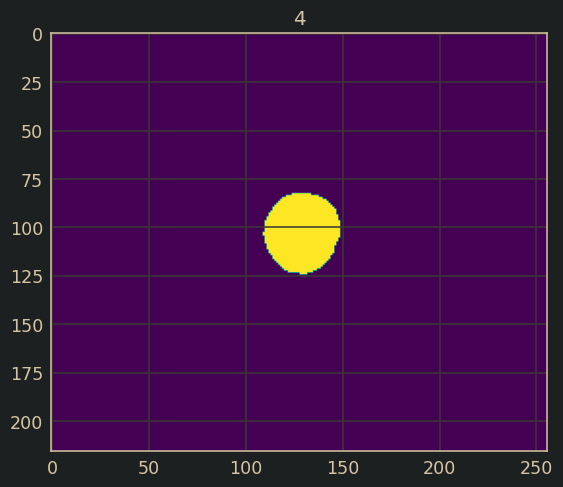

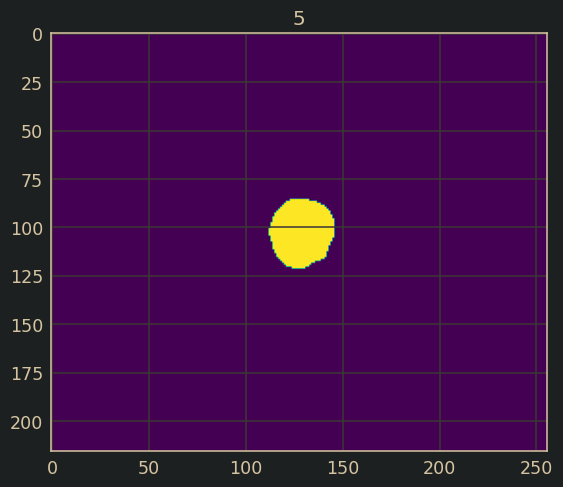

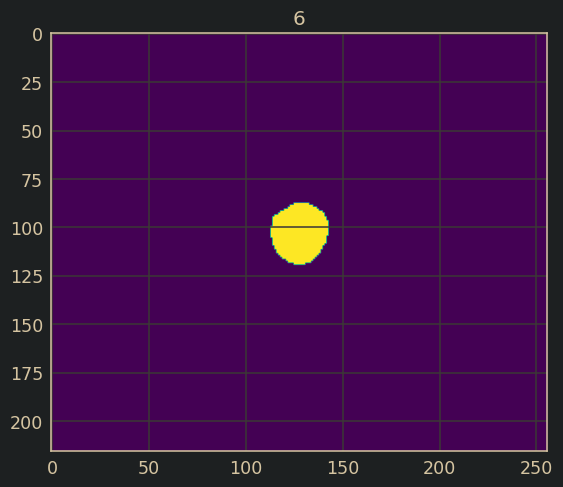

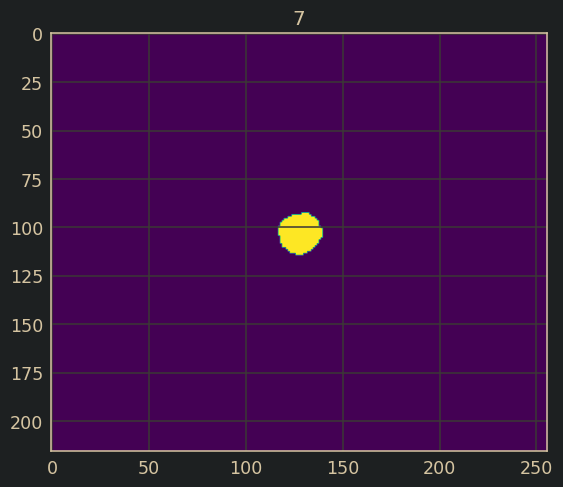

In [8]:
# Show slices for original volume 0
for idx in range(M.shape[0]):
    plt.imshow(M[idx])
    plt.title(idx)
    plt.show()

### Interpolate results for 3D input

# Show slices for generated volume
for idx in range(vol.shape[0]):
    plt.imshow(vol[idx])
    plt.title(f"Index {idx}")
    plt.show()

## Show result in PyVista

DEBUG: Creating constraints.
(1542, 4)
DEBUG: Finished creating constraints.
Elapsed time: 0.30013346672058105

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/1542 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 0.6950032711029053

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.03466081619262695
Output dimensions: (10, 216, 256)
Threshold: 0.0


Interpolating volume stack:   0%|          | 0/2160 [00:00<?, ?it/s]

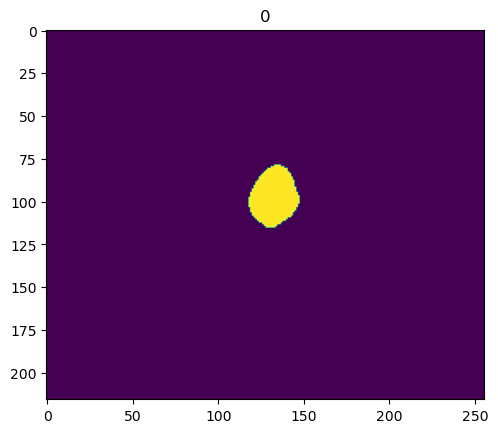

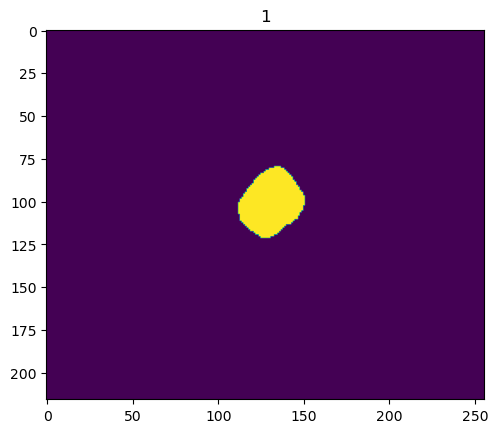

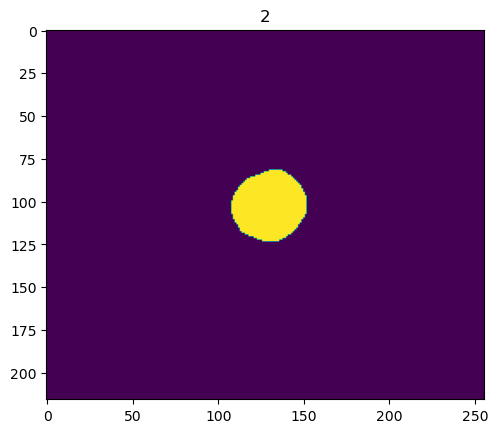

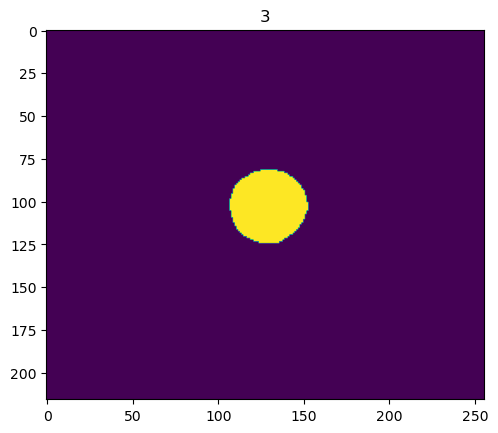

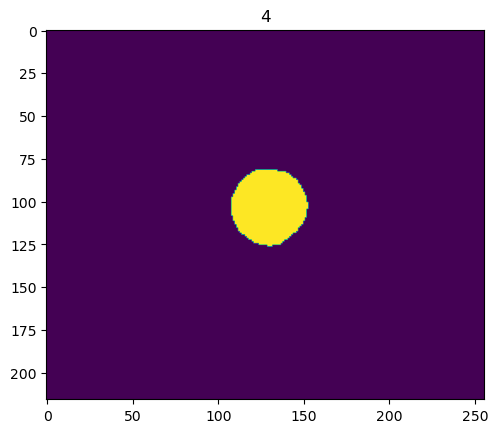

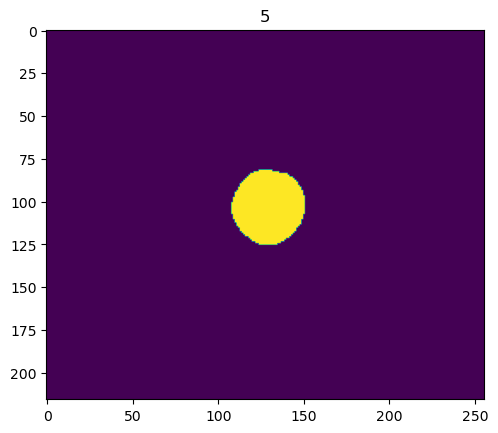

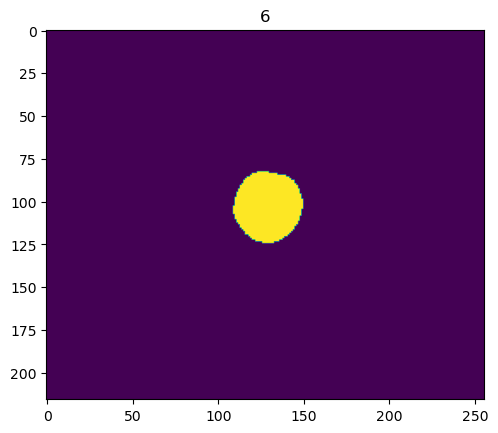

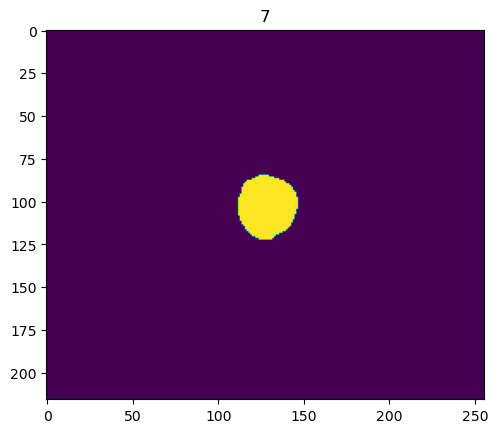

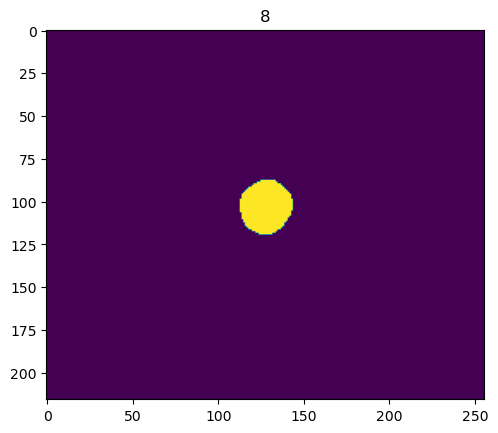

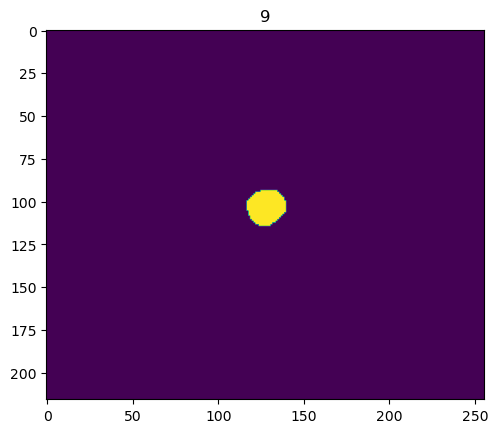

In [16]:
Ma = volume[0, :]
Mb = volume[15, :]
Mab = np.array([Ma, Mb])

imp = ImplicitFunction(Mab, tmax=1, grid_spacing=0)

img = imp.interpolate(0.5, postprocess=True, kernel_size=4)
np.save('output/anim/step2/M0-M15-0.5.npy', img)

for i in range(len(img)):
    plt.title(str(i))
    plt.imshow(img[i])
    plt.show()

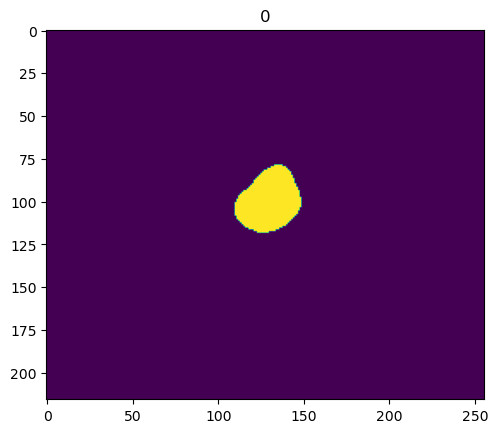

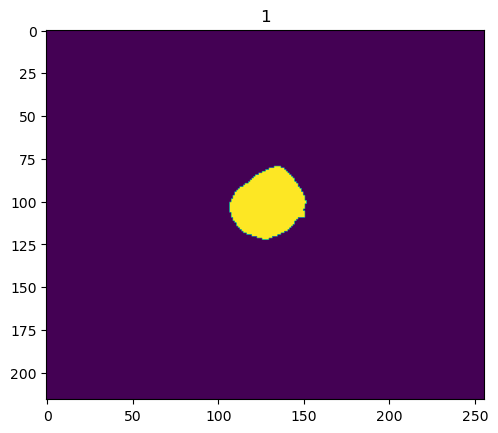

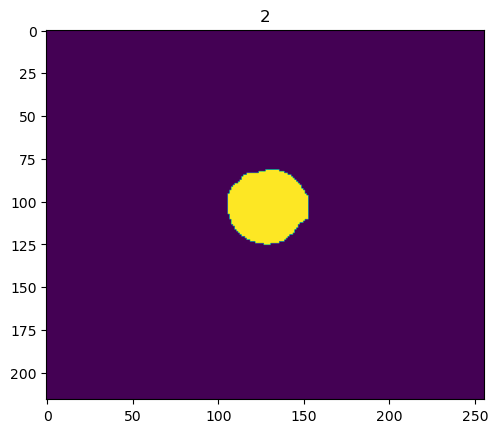

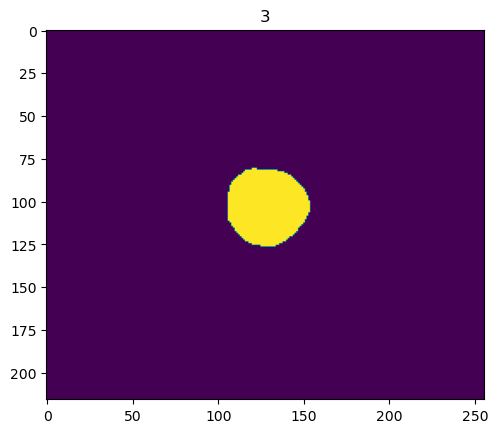

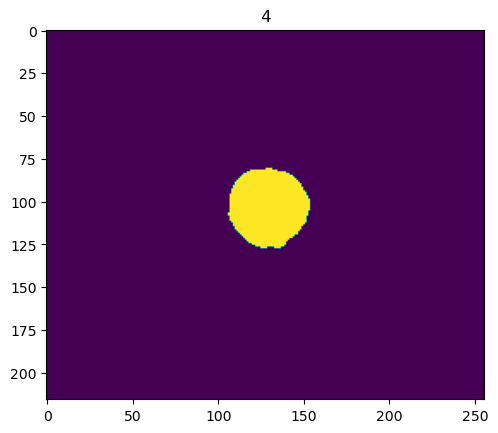

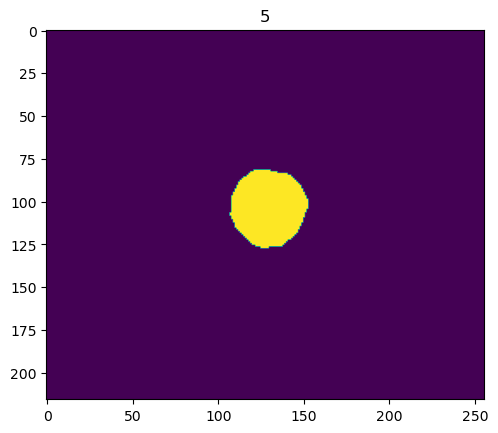

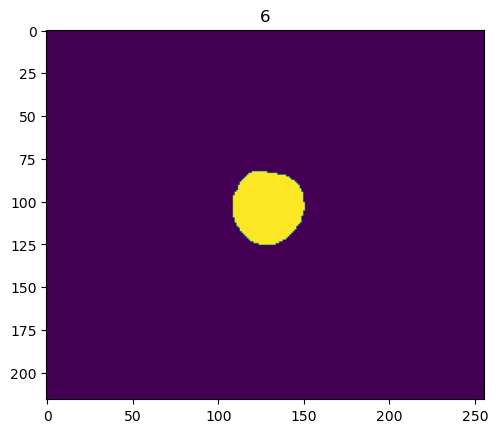

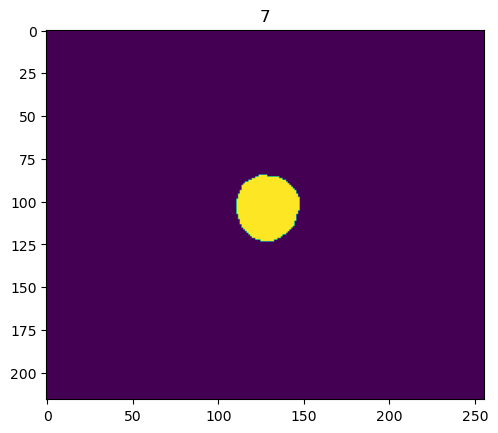

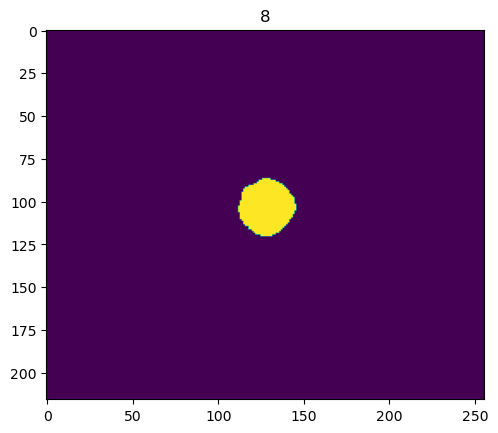

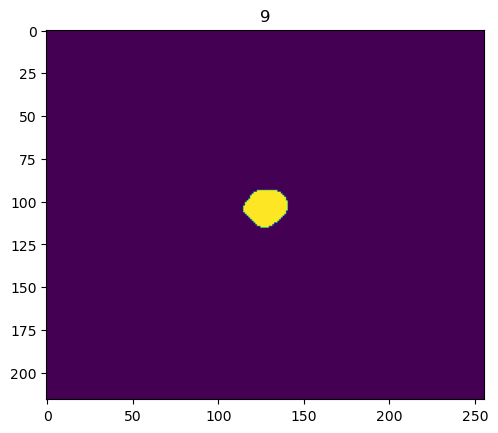

In [18]:
npy_path = 'output/anim/full_4d_interp/4DLV_interp-1.0.npy'
npy_img = np.load(npy_path)

for i in range(len(npy_img)):
    plt.title(str(i))
    plt.imshow(npy_img[i])
    plt.show()

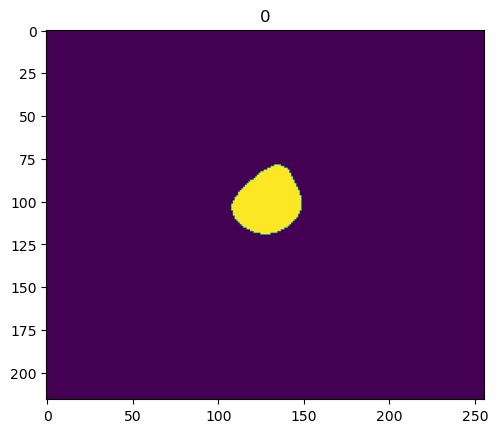

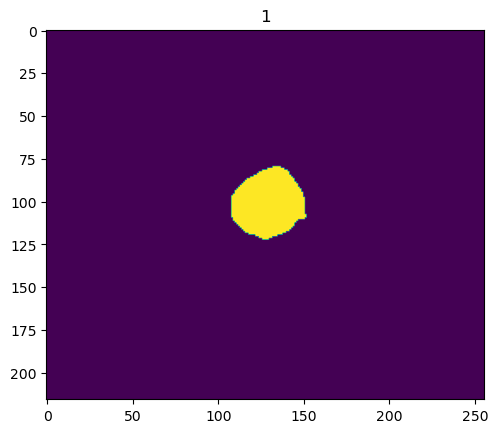

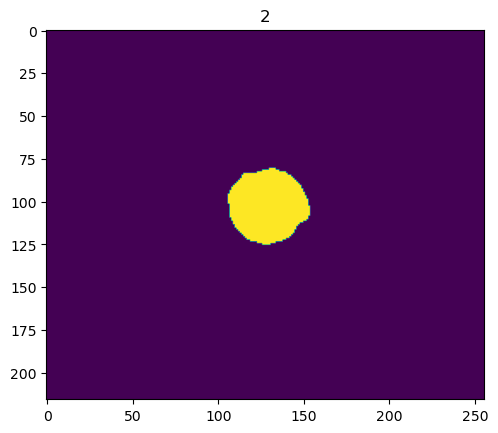

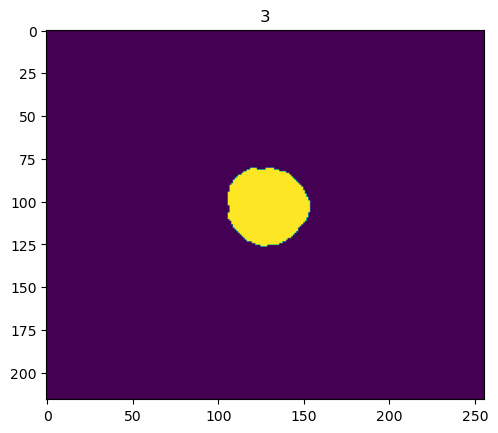

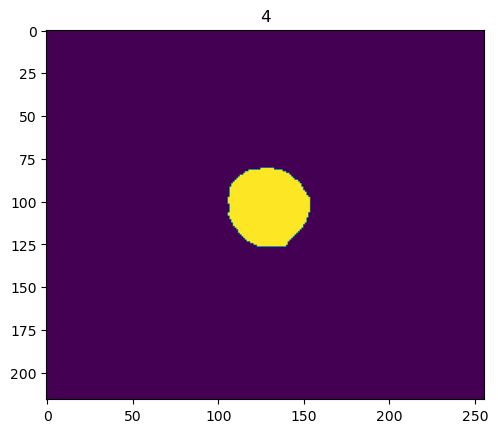

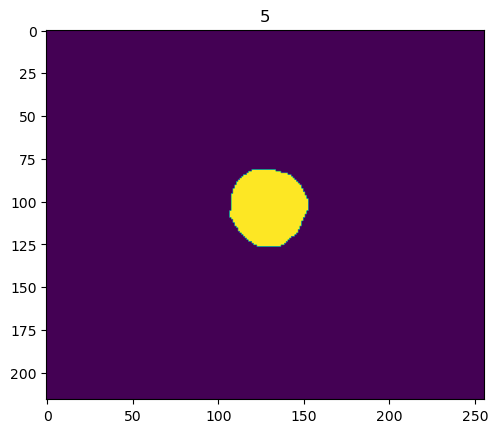

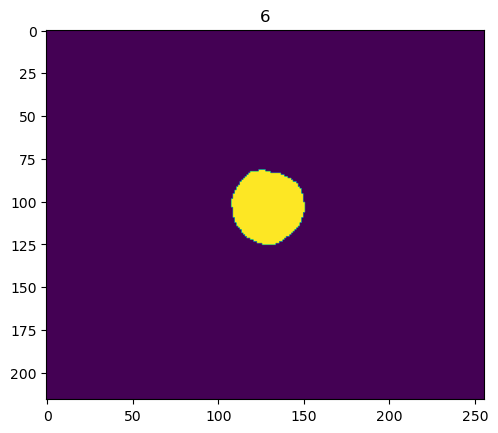

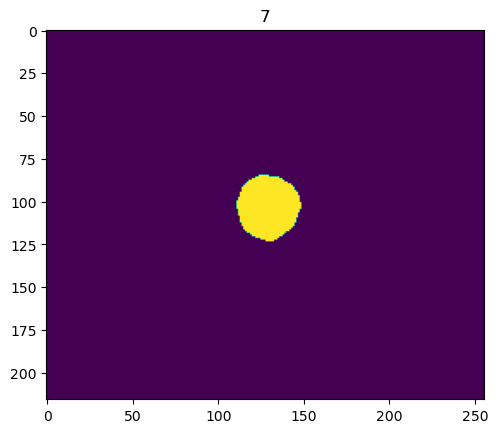

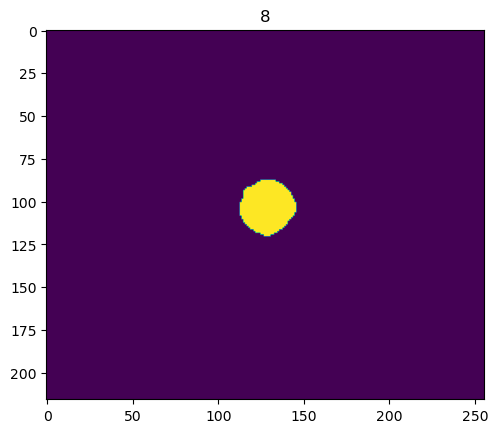

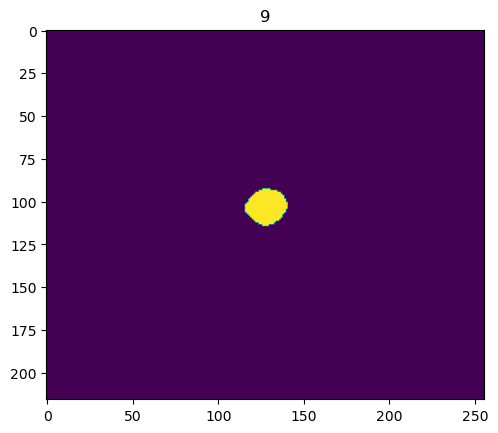

In [27]:
npy_path = 'output/anim/step/M1-M2-2.npy'
npy_img = np.load(npy_path)

for i in range(len(npy_img)):
    plt.title(str(i))
    plt.imshow(npy_img[i])
    plt.show()